Checkpoint #2 

Part a

In [71]:
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

churn = pd.read_csv('netflix_customer_churn.csv')

churn["watch_hours"] = churn["watch_hours"].round().astype(int)
churn = churn[churn["avg_watch_time_per_day"] <= 24]          # impossible values

churn.head()

,customer_id,age,gender,subscription_type,watch_hours,last_login_days,region,device,monthly_fee,churned,payment_method,number_of_profiles,avg_watch_time_per_day,favorite_genre
0,a9b75100-82a8-427a-a208-72f24052884a,51,Other,Basic,15,29,Africa,TV,8.99,1,Gift Card,1,0.49,Action
1,49a5dfd9-7e69-4022-a6ad-0a1b9767fb5b,47,Other,Standard,1,19,Europe,Mobile,13.99,1,Gift Card,5,0.03,Sci-Fi
2,4d71f6ce-fca9-4ff7-8afa-197ac24de14b,27,Female,Standard,16,10,Asia,TV,13.99,0,Crypto,2,1.48,Drama
3,d3c72c38-631b-4f9e-8a0e-de103cad1a7d,53,Other,Premium,5,12,Oceania,TV,17.99,1,Crypto,2,0.35,Horror
4,4e265c34-103a-4dbb-9553-76c9aa47e946,56,Other,Standard,2,13,Africa,Mobile,13.99,1,Crypto,2,0.13,Action


Part B: Do the customers who churn watch fewer hours of Netflix than those who are still subscribed? 

Subscribed mean: 17.35
Churned mean: 5.91


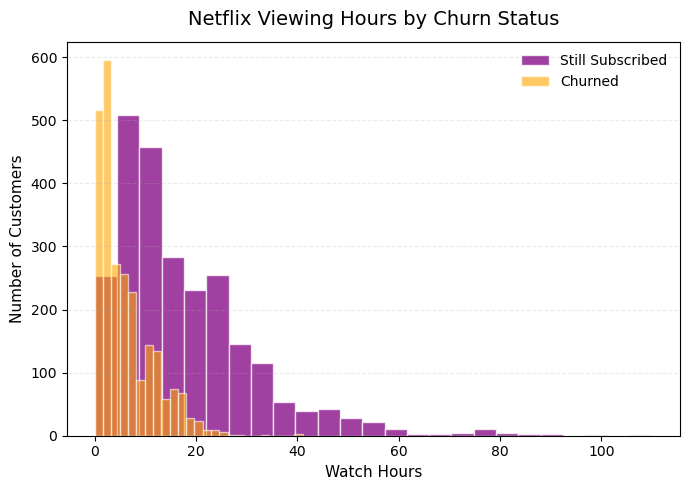

In [72]:
# Separate viewing hours by churn status
subscribed = churn[churn["churned"] == 0]["watch_hours"].dropna()
churned = churn[churn["churned"] == 1]["watch_hours"].dropna()

print("Subscribed mean:", round(subscribed.mean(), 2))
print("Churned mean:", round(churned.mean(), 2))

# Create box plot
plt.figure(figsize=(7, 5))

plt.hist(subscribed, bins=25, alpha=0.75, label="Still Subscribed",
         edgecolor="white", linewidth=1, color="purple")

plt.hist(churned, bins=25, alpha=0.6, label="Churned",
         edgecolor="white", linewidth=1, color="orange")

plt.title("Netflix Viewing Hours by Churn Status", fontsize=14, pad=12)
plt.xlabel("Watch Hours", fontsize=11)
plt.ylabel("Number of Customers", fontsize=11)

plt.grid(axis="y", linestyle="--", alpha=0.25)
plt.legend(frameon=False)
plt.tight_layout()
plt.show()

In [73]:
t_stat, p_value = stats.ttest_ind(churned, subscribed, equal_var=False, alternative="less")

print("t-statistic:", round(t_stat, 4))
print("p-value:", f"{p_value:.2e}")

alpha = 0.05

if p_value < alpha:
    print("Reject the null hypothesis.")
    print(
        f"The hypothesis test produced a t-statistic of {t_stat:.4f} "
        f"and a p-value of {p_value:.2e}, which is smaller than 0.05. "
        "Therefore, we reject the null hypothesis. There is statistically "
        "significant evidence to say that customers who churn watch fewer hours "
        "of Netflix than customers who remain subscribed.")
else:
    print("Fail to reject the null hypothesis.")
    print(
        f"The hypothesis test produced a t-statistic of {t_stat:.4f} "
        f"and a p-value of {p_value:.2e}, which is greater than or equal "
        "to 0.05. Therefore, we fail to reject the null hypothesis. "
        "There is insufficient statistical evidence to say that customers who "
        "churn watch fewer hours of Netflix than customers who remain subscribed.")


t-statistic: -38.3832
p-value: 6.20e-266
Reject the null hypothesis.
The hypothesis test produced a t-statistic of -38.3832 and a p-value of 6.20e-266, which is smaller than 0.05. Therefore, we reject the null hypothesis. There is statistically significant evidence to say that customers who churn watch fewer hours of Netflix than customers who remain subscribed.


Part C: Do Basic-plan customers churn more than Standard or Premium customers?

                   Still Subscribed  Churned
subscription_type                           
Basic                           630     1027
Standard                        895      748
Premium                         950      740

Churn rate by plan (%):
subscription_type
Basic       62.0
Standard    45.5
Premium     43.8
Name: churned, dtype: float64


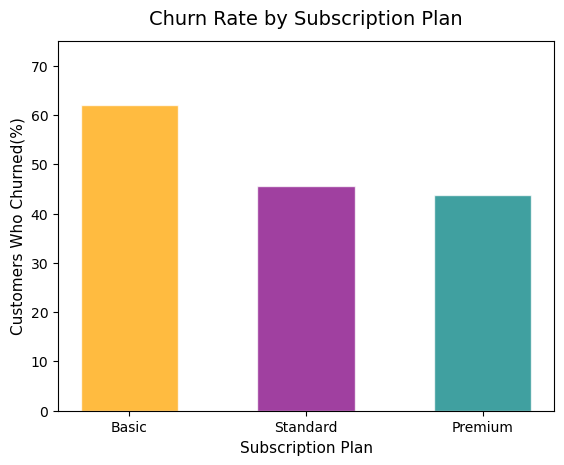


Chi-square statistic: 134.0519
Degrees of freedom: 2
p-value: 7.78e-30
Reject the null hypothesis.
The chi-square test of independence produced a chi-square statistic of 134.0519 with 2 degrees of freedomand a p-value of 7.78e-30, which is smaller than 0.05. Therefore, we reject the null hypothesis. There is statistically significant evidence to say that churn depends on subcription plan. Basic-plan customers churned 62.0%, compared with 45.5% for Standard and 43.8% for Premium.


In [74]:
plan_order = ["Basic", "Standard", "Premium"]

table = (churn.groupby("subscription_type")["churned"]
         .value_counts()
         .unstack()
         .loc[plan_order])
table.columns = ["Still Subscribed", "Churned"]
print(table)

churn_rate = churn.groupby("subscription_type")["churned"].mean().loc[plan_order] * 100
print("\nChurn rate by plan (%):")
print(churn_rate.round(1))

bars = plt.bar(plan_order, churn_rate, width=0.55,
               color=["orange", "purple", "teal"], alpha=0.75,
               edgecolor="white", linewidth=1)

plt.title("Churn Rate by Subscription Plan", fontsize=14, pad=12)
plt.xlabel("Subscription Plan", fontsize=11)
plt.ylabel("Customers Who Churned(%)", fontsize=11)
plt.ylim(0, 75)

plt.show()

chi2, p_value, dof, expected = stats.chi2_contingency(table)

print("\nChi-square statistic:", round(chi2, 4))
print("Degrees of freedom:", dof)
print("p-value:", f"{p_value:.2e}")

alpha = 0.05

if p_value < alpha:
    print("Reject the null hypothesis.")
    print(
        f"The chi-square test of independence produced a chi-square statistic of "
        f"{chi2:.4f} with {dof} degrees of freedomand a p-value of {p_value:.2e}, "
        "which is smaller than 0.05. Therefore, we reject the null hypothesis. "
        "There is statistically significant evidence to say that churn depends on "
        "subcription plan. Basic-plan customers churned "
        f"{churn_rate['Basic']:.1f}%, compared with {churn_rate['Standard']:.1f}% "
        f"for Standard and {churn_rate['Premium']:.1f}% for Premium.")
else:
    print("Fail to reject the null hypothesis.")
    print(
        f"The chi-square test of independence produced a chi-square statistic of "
        f"{chi2:.4f} with {dof} degrees of freedom and a p-value of {p_value:.2e}, "
        "which is greater than or equal to 0.05. Therefore, we fail to reject the null hypothesis. "
        "There is insufficient statistical evidence to say that churn depends on subscription plan.")





Part D: Are there outliers?

In data science, we take and process samples from a large, diverse population. In doing so, there is bound to be certain data points that differ significantly from the majority of the values within a given data set, those are outliers. Outliers can occur due data entry errors, measurement errors, or genuine differences in behavior. 

Identifying outliers is an important part of data cleaning and exploratory data analysis because it can affect how we understand our data and the conclusions we make from it. For example, an extremely high value can pull the average up and make it seem like customers watch more NetFlix than they actually do on a regular basis. In other words, these outliers can skew data by pulling the arithmetic mean and inflate the standard deviation, leading to distorted correlations and regressions. 

While it may seem better to automatically remove outliers from a dataset (valid method), in cases where there are genuine differences in behavior, erasing outliers forgoes significant patterns that we can gain insight from. This is why we need to investigate outliers carefully instead of automatically removing them. 

In our dataset (netflix_customer_churn.csv), it contains both numerical and categorical data types for our columns. For numerical data types, we can use statistical methods like the interquartile range, or IQR, to identify values that fall far outside the typical range of our data. For categorical data types, we can use a frequency table to identify categories that are significantly less or more common than others. 

In [75]:
# Get all numerical columns
numeric_cols = churn.select_dtypes(include=['int64', 'float64']).columns.drop(['churned', 'monthly_fee']) # Exclude churned (1 or 0 values) and monthly_fee (its fixed prices)
for col in numeric_cols: # Find outliers using interquantile ranges
    Q1 = churn[col].quantile(0.25)
    Q3 = churn[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = churn[(churn[col] < lower) | (churn[col] > upper)]

    print(f"\n{col}")
    print(f"Number of outliers: {len(outliers)}")
    print(outliers[col].to_list())

# Get categorical columns
categorical_cols = churn.select_dtypes(include=['object']).columns.drop('customer_id') # Exclude customer_id as they are unique to individual customers
for col in categorical_cols:
    counts = churn[col].value_counts()
    percentages = churn[col].value_counts(normalize=True) * 100

    print(f"\n{col}")
    print(pd.DataFrame({'Count': counts, 'Percentage': percentages.round(2)}))


age
Number of outliers: 0
[]

watch_hours
Number of outliers: 228
[41, 43, 47, 49, 48, 38, 79, 36, 40, 45, 38, 48, 52, 51, 71, 38, 42, 48, 37, 42, 41, 41, 92, 45, 60, 87, 38, 52, 46, 63, 56, 41, 47, 41, 41, 48, 55, 41, 54, 49, 67, 36, 55, 47, 53, 66, 38, 42, 59, 56, 39, 49, 47, 49, 76, 50, 81, 37, 55, 46, 56, 40, 51, 40, 44, 41, 36, 53, 77, 54, 71, 36, 37, 59, 79, 42, 50, 39, 78, 46, 49, 45, 42, 36, 45, 48, 57, 46, 36, 52, 41, 46, 60, 61, 78, 36, 47, 48, 36, 38, 40, 68, 51, 51, 60, 38, 47, 40, 45, 80, 56, 39, 43, 54, 36, 51, 39, 58, 38, 44, 39, 36, 63, 55, 42, 36, 48, 54, 39, 37, 83, 36, 48, 39, 36, 52, 36, 61, 49, 37, 36, 84, 51, 41, 36, 42, 46, 83, 37, 42, 76, 39, 40, 50, 36, 54, 37, 40, 42, 90, 46, 47, 53, 38, 41, 76, 46, 44, 76, 44, 36, 48, 50, 110, 45, 38, 36, 44, 43, 49, 36, 50, 60, 36, 40, 78, 49, 76, 41, 44, 39, 47, 36, 43, 39, 41, 45, 58, 101, 43, 47, 36, 38, 47, 39, 55, 47, 37, 62, 51, 43, 43, 52, 40, 47, 51, 56, 37, 41, 41, 54, 55, 46, 71, 49, 71, 43, 49]

last_login_days
N

From these results, we can see that there are numerical outliers in watch_hours and avg_watch_time_per_day while there isn't any in age, last_login_days, and number_of_profiles. If you comb through some of the values in avg_watch_time_per_day, you find some crazy values such as 21.21 hours! However, these unusual values are not necessarily errors or bad data as they could represent genuine differences in customer behavior or demographics that are worth investigating further (21 hours-per-day is a possibility but questionable). When exploring data, you may need to keep an eye out for impossible values (>24 hours) as they could be likely results of faulty equipment or incorrect measurements (ex. minutes instead of hours). You should remove these values from your data set, we done ours earlier with churn = churn[churn["avg_watch_time_per_day"] <= 24]!

On the categorical aspect, we don't really see any significant differences between the categories in each column. This suggests that our categorical data is relatively balanced in terms of its distribution, and we don't have any immediately noticeable unusual patterns that require further investigation.

However, the best way to find outliers is to visually represent it. Pay close attention to the avg_watch_time_per_day graph.

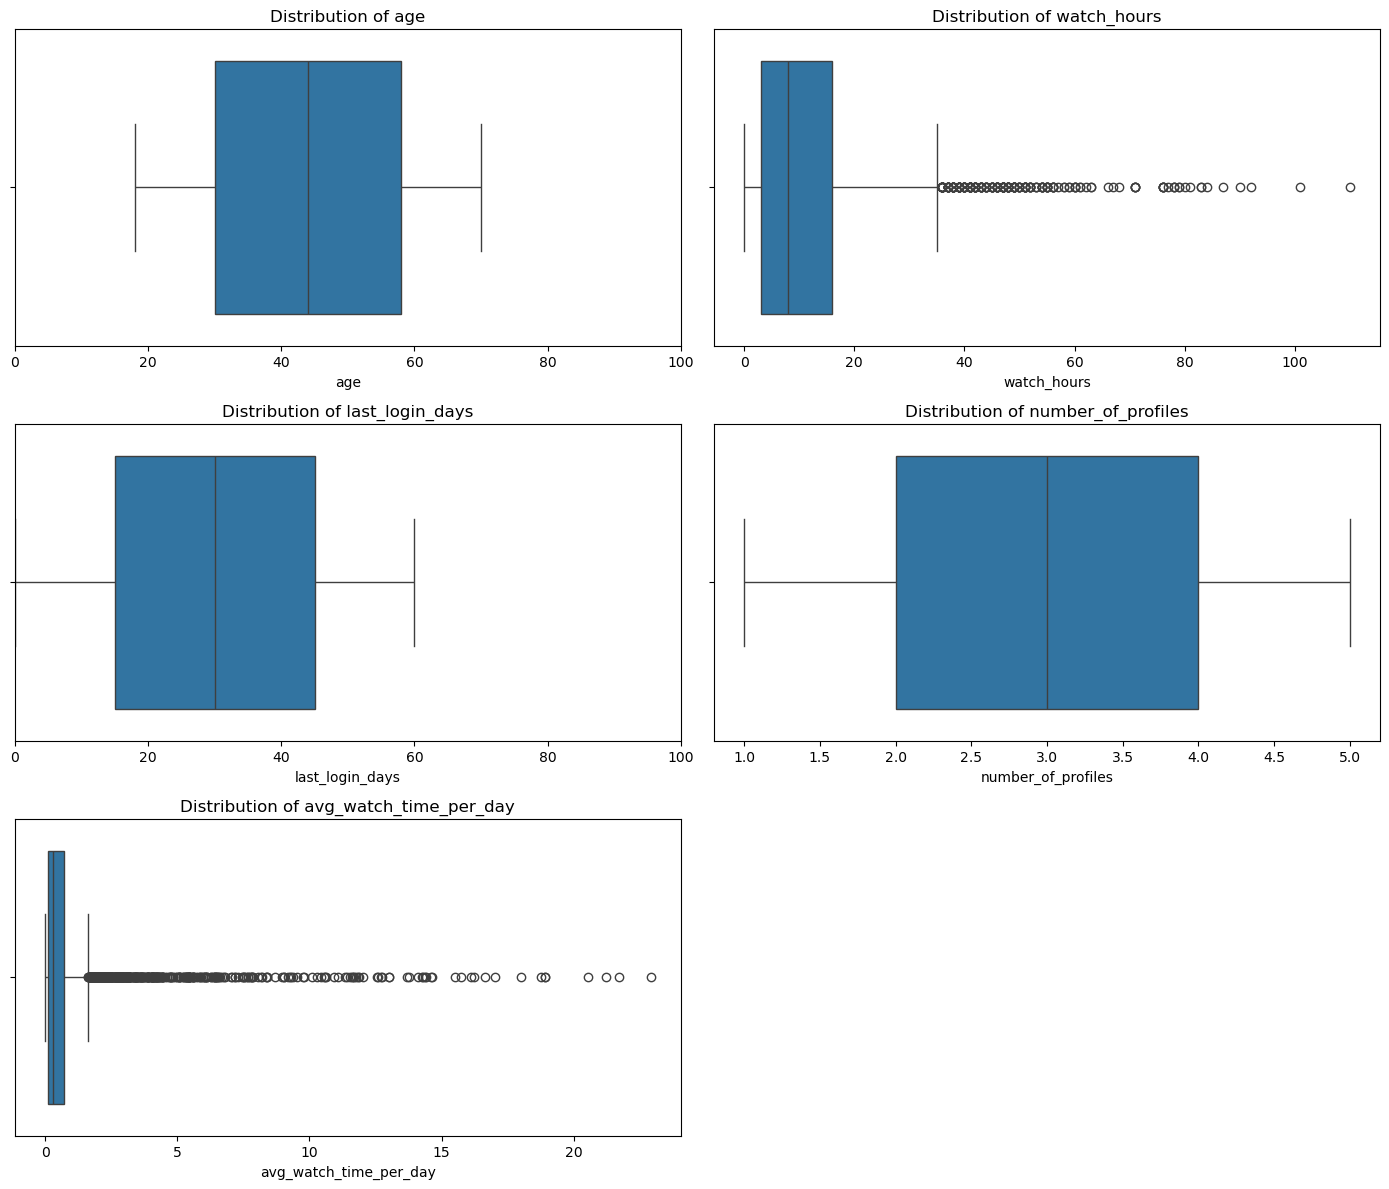

In [76]:
numeric_cols = churn.select_dtypes(include='number').columns.drop(['monthly_fee', 'churned'], errors='ignore')

fig, axes = plt.subplots(3, 2, figsize=(14, 12))

# Make axes easier to work with
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    sns.boxplot(data=churn, x=col, ax=axes[i])
    axes[i].set_title(f'Distribution of {col}')
    axes[i].set_xlabel(col)

    # Set x-axis from 0 to 100 for age and last login
    if col in ['age', 'last_login_days']:
        axes[i].set_xlim(0, 100)

# Hide any unused graph spaces
for i in range(len(numeric_cols), len(axes)):
    axes[i].set_visible(False)

plt.tight_layout()
plt.show()